# Exploratory Data Analysis
- Statistical Analysis
- Visualization

In [1]:
# Imports
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# Load Data
KNOWN_DATA_PATH = r"C:\Users\hp\Downloads\BIA\E-commerce_Customer_Segmentation_and_Prediction\data\known.csv"
data= pd.read_csv(KNOWN_DATA_PATH, parse_dates=['InvoiceDate'])
data.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,Day,Hour,DayOfWeek,TotalPrice,Return
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,2010,12,1,8,Wednesday,15.30,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,1,8,Wednesday,20.34,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,2010,12,1,8,Wednesday,22.00,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,1,8,Wednesday,20.34,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,2010,12,1,8,Wednesday,20.34,False


In [3]:
# Statistical Analysis
df= data.copy()
df.describe(include= 'all')

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Year,Month,Day,Hour,DayOfWeek,TotalPrice,Return
count,401602,401602,401602,401602.000000,401602,401602.000000,401602.000000,401602,401602.000000,401602.000000,401602.00000,401602.000000,401602,401602.000000,401602
unique,22190,3684,3666,NaN,NaN,NaN,NaN,37,NaN,NaN,NaN,NaN,6,NaN,2
top,576339,85123A,WHITE HANGING HEART T-LIGHT HOLDER,NaN,NaN,NaN,NaN,United Kingdom,NaN,NaN,NaN,NaN,Thursday,NaN,False
freq,542,2065,2065,NaN,NaN,NaN,NaN,356726,NaN,NaN,NaN,NaN,81575,NaN,392730
mean,NaN,NaN,NaN,12.182579,2011-07-10 12:08:08.129839872,3.474064,15281.172576,NaN,2010.934378,7.595405,15.03862,12.731035,NaN,20.612366,NaN
min,NaN,NaN,NaN,-80995.000000,2010-12-01 08:26:00,0.000000,12346.000000,NaN,2010.000000,1.000000,1.00000,6.000000,NaN,-168469.600000,NaN
25%,NaN,NaN,NaN,2.000000,2011-04-06 15:02:00,1.250000,13939.000000,NaN,2011.000000,5.000000,7.00000,11.000000,NaN,4.250000,NaN
50%,NaN,NaN,NaN,5.000000,2011-07-29 15:40:00,1.950000,15145.000000,NaN,2011.000000,8.000000,15.00000,13.000000,NaN,11.700000,NaN
75%,NaN,NaN,NaN,12.000000,2011-10-20 11:58:00,3.750000,16784.000000,NaN,2011.000000,11.000000,22.00000,14.000000,NaN,19.800000,NaN
max,NaN,NaN,NaN,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000,NaN,2011.000000,12.000000,31.00000,20.000000,NaN,168469.600000,NaN


In [4]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%Y %H:%M')

### Key Wise Data Insights

In [6]:
# 1. Country-wise Customer Distribution
df["Country"].value_counts().head()

Country
United Kingdom    356726
Germany             9480
France              8475
EIRE                7475
Spain               2528
Name: count, dtype: int64

**Most Active Countries:** Analyze transaction volumes by country to understand geographical demand and tailor marketing strategies.

In [7]:
#  High-Valued Products
df.groupby("Description").agg({"UnitPrice":"max"}).sort_values("UnitPrice", ascending = False).head()

,UnitPrice
Description,
Manual,38970.00
POSTAGE,8142.75
Discount,1867.86
DOTCOM POSTAGE,1599.26
CRUK Commission,1100.44


**High-Priced Products:** Identify products with the highest prices to guide pricing strategies and inventory management.

In [8]:
#High Revenue Generating Products
top_products = df.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10)
top_products

Description
REGENCY CAKESTAND 3 TIER              132567.70
WHITE HANGING HEART T-LIGHT HOLDER     93923.15
JUMBO BAG RED RETROSPOT                83056.52
PARTY BUNTING                          67628.43
POSTAGE                                66710.24
ASSORTED COLOUR BIRD ORNAMENT          56331.91
RABBIT NIGHT LIGHT                     51042.84
PICNIC BASKET WICKER SMALL             46963.10
CHILLI LIGHTS                          45915.41
PAPER CHAIN KIT 50'S CHRISTMAS         41423.78
Name: TotalPrice, dtype: float64

**Top Revenue-Generating Products:**
Identify the top 10 products contributing the most to revenue.
Use these insights for targeted promotions and marketing.

In [9]:
# Total Quantity Sold
df.groupby("Description").agg({"Quantity":"sum"}).head()

,Quantity
Description,
4 PURPLE FLOCK DINNER CANDLES,138
50'S CHRISTMAS GIFT BAG LARGE,1907
DOLLY GIRL BEAKER,2387
I LOVE LONDON MINI BACKPACK,360
NINE DRAWER OFFICE TIDY,54


**Total Quantity Sold per Product:**
Analyze total sales by product description to aid inventory forecasting.
Understand customer preferences better.

In [10]:
# Unique Invoices
df["InvoiceNo"].nunique()

22190

**Transaction Volume:**
Count unique invoice numbers to understand the total number of transactions.

In [11]:
# First Invoice Date
df['InvoiceDate'].iloc[0]

Timestamp('2010-12-01 08:26:00')

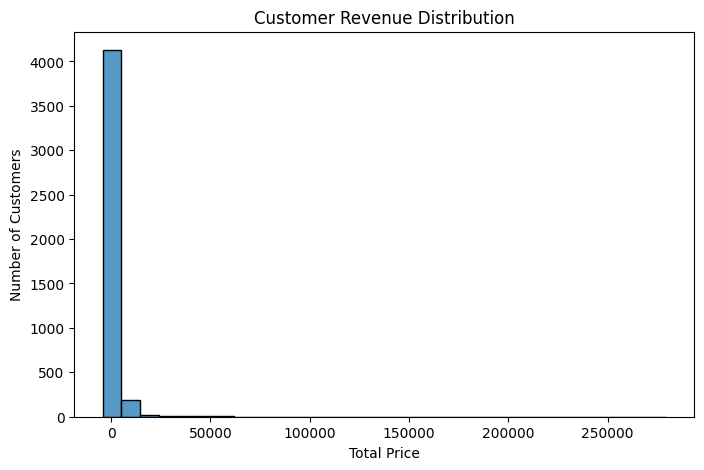

In [12]:
#total revenue per customer
customer_revenue = df.groupby('CustomerID')['TotalPrice'].sum()

#purchase frequency per customer
purchase_frequency = df.groupby('CustomerID')['InvoiceNo'].count()

#average order value per customer
average_order_value = customer_revenue / purchase_frequency

# purchase patterns over time
df['InvoiceMonth'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('InvoiceMonth')['TotalPrice'].sum()


# Visualize customer revenue distribution
plt.figure(figsize=(8, 5))
sns.histplot(customer_revenue, bins=30)
plt.title('Customer Revenue Distribution')
plt.xlabel('Total Price')
plt.ylabel('Number of Customers')
plt.show()

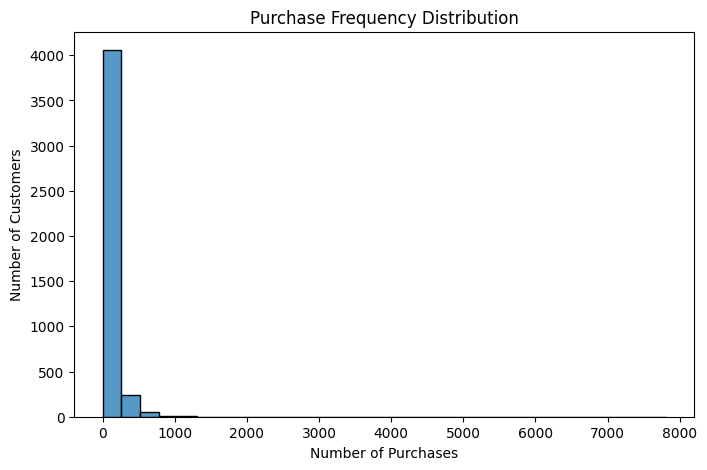

In [13]:
# Visualize purchase frequency distribution
plt.figure(figsize=(8, 5))
sns.histplot(purchase_frequency, bins=30)
plt.title('Purchase Frequency Distribution')
plt.xlabel('Number of Purchases')
plt.ylabel('Number of Customers')
plt.show()

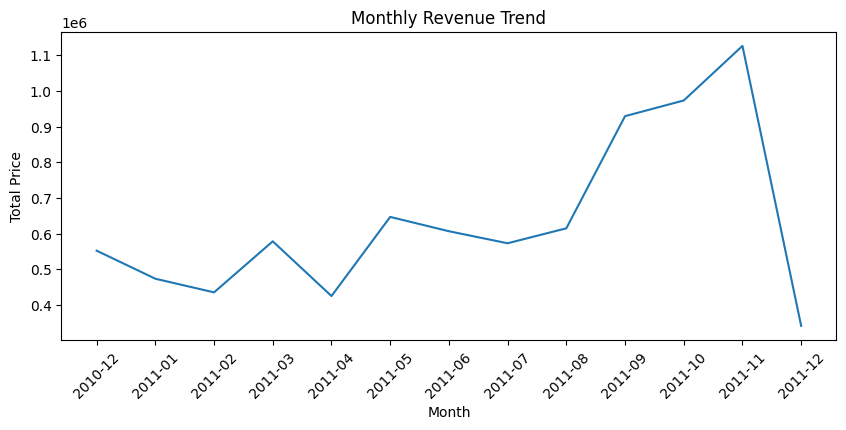

In [14]:
# Visualize monthly revenue trends
plt.figure(figsize=(10, 4))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values)
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Total Price')
plt.xticks(rotation=45)
plt.show()

**Revenue Trends:**
Create a line chart showing revenue over time to identify seasonal patterns.

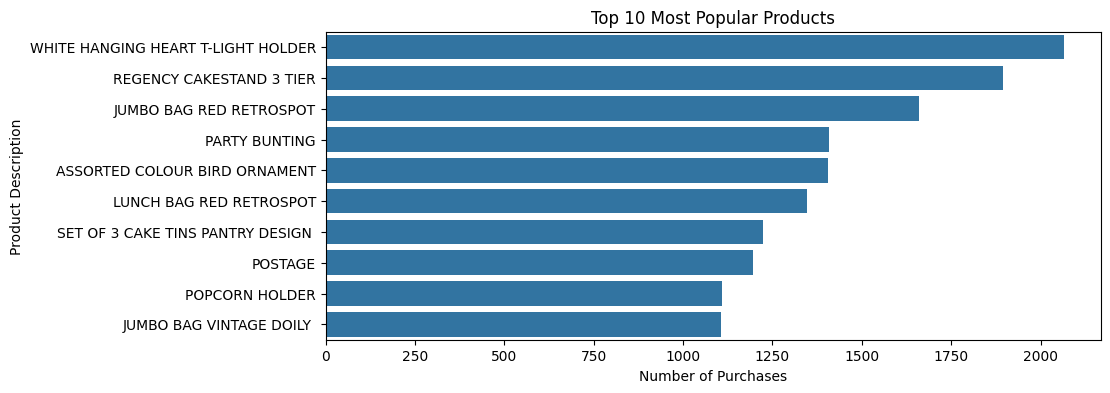

In [15]:
# Analyze product popularity
product_popularity = df['Description'].value_counts().head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=product_popularity.values, y=product_popularity.index)
plt.title('Top 10 Most Popular Products')
plt.xlabel('Number of Purchases')
plt.ylabel('Product Description')
plt.show()

**Most Purchased Products:**
Use a bar chart to highlight popular products, informing stock and marketing decisions.

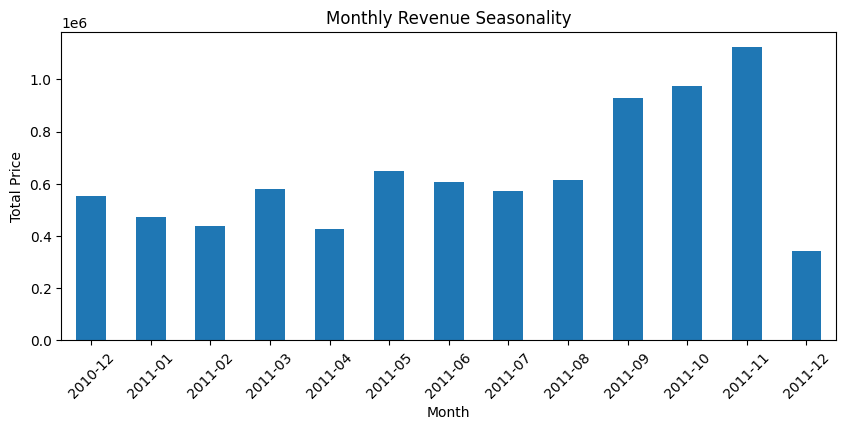

In [16]:
# Analyze sales seasonality using monthly revenue data
plt.figure(figsize=(10, 4))
monthly_revenue.plot(kind='bar')
plt.title('Monthly Revenue Seasonality')
plt.xlabel('Month')
plt.ylabel('Total Price')
plt.xticks(rotation=45)
plt.show()

**Monthly Revenue Distribution:**
Visualize revenue trends across months to identify sales peaks.

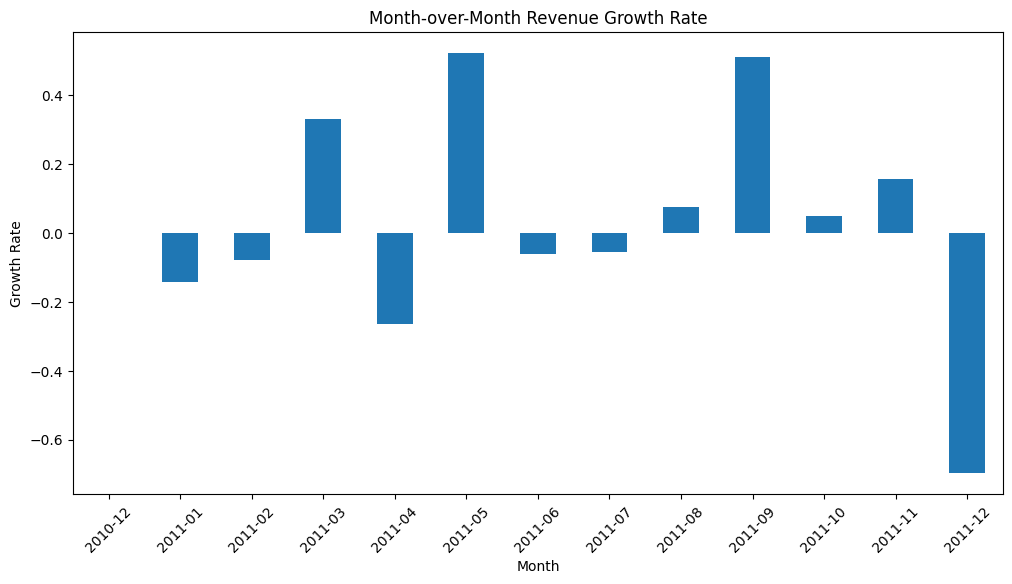

In [17]:
# Calculate and visualize the month-over-month revenue growth rate
monthly_revenue_growth = monthly_revenue.pct_change()
plt.figure(figsize=(12, 6))
monthly_revenue_growth.plot(kind='bar')
plt.title('Month-over-Month Revenue Growth Rate')
plt.xlabel('Month')
plt.ylabel('Growth Rate')
plt.xticks(rotation=45)
plt.show()

**Revenue Growth Rates:**
Plot month-over-month growth rates to assess financial health.

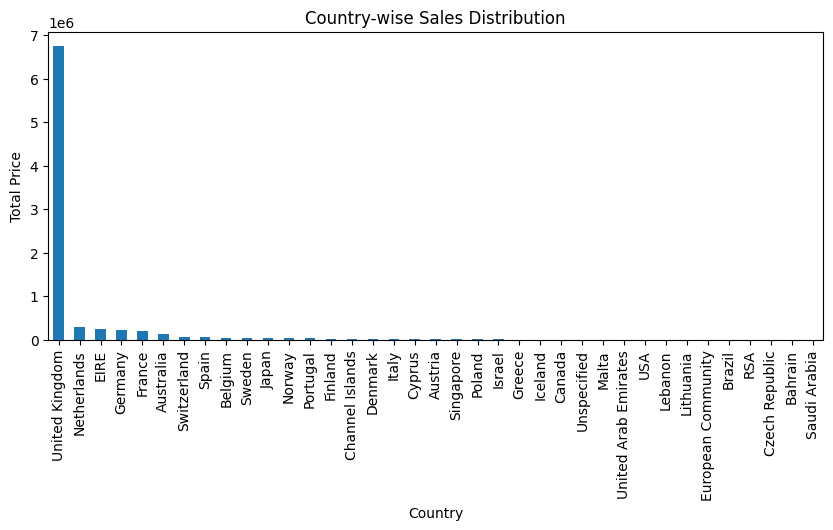

In [18]:
# Country-wise Sales Distribution
country_sales = df.groupby('Country')['TotalPrice'].sum().sort_values(ascending=False)

# Visualize country-wise sales distribution
plt.figure(figsize=(10, 4))
country_sales.plot(kind='bar')
plt.title('Country-wise Sales Distribution')
plt.xlabel('Country')
plt.ylabel('Total Price')
plt.xticks(rotation=90)
plt.savefig('country_sales_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

            Quantity  UnitPrice  CustomerID      Year     Month       Day  \
Quantity    1.000000  -0.001243   -0.003453  0.001040 -0.002357 -0.000235   
UnitPrice  -0.001243   1.000000   -0.004524  0.000978 -0.003140 -0.001911   
CustomerID -0.003453  -0.004524    1.000000 -0.035277  0.029856 -0.001929   
Year        0.001040   0.000978   -0.035277  1.000000 -0.341561  0.166678   
Month      -0.002357  -0.003140    0.029856 -0.341561  1.000000 -0.117815   
Day        -0.000235  -0.001911   -0.001929  0.166678 -0.117815  1.000000   
Hour       -0.008341   0.001715    0.064076 -0.019676  0.055715  0.007865   
TotalPrice  0.916130  -0.129311   -0.002126 -0.000214 -0.001814 -0.000746   
Return     -0.025797   0.033233   -0.025520 -0.006759 -0.012708 -0.004636   

                Hour  TotalPrice    Return  
Quantity   -0.008341    0.916130 -0.025797  
UnitPrice   0.001715   -0.129311  0.033233  
CustomerID  0.064076   -0.002126 -0.025520  
Year       -0.019676   -0.000214 -0.006759  
Mont

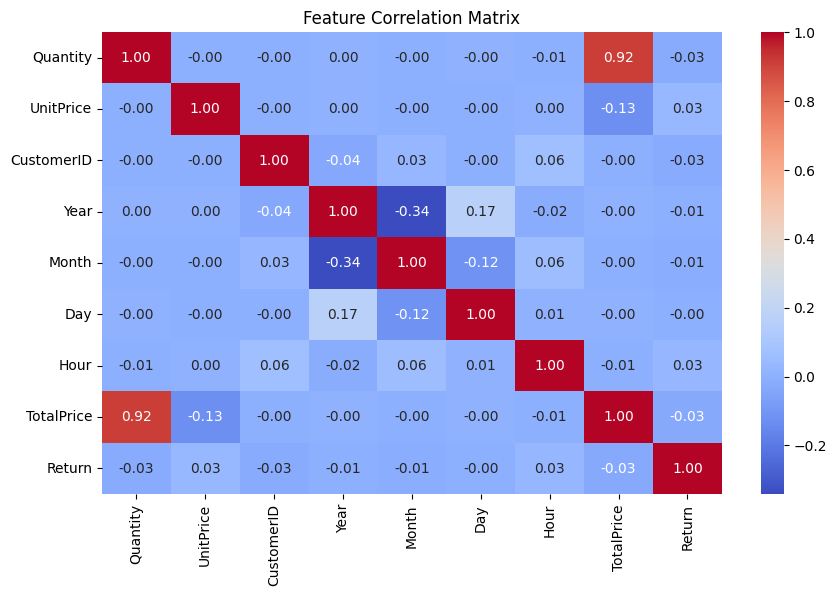

In [19]:
corr = df.corr(numeric_only=True)

# Print values
print(corr)

# Heatmap (VERY IMPORTANT for analysis)
plt.figure(figsize=(10,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Feature Correlation Matrix")
plt.show()

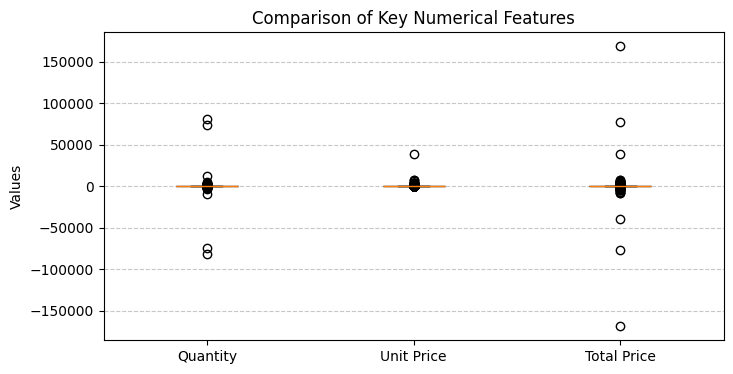

In [22]:
# Multiple Box Plots
plt.figure(figsize=(8,4))

data = [df['Quantity'], df['UnitPrice'], df['TotalPrice']]
labels = ['Quantity', 'Unit Price', 'Total Price']

plt.boxplot(data, tick_labels=labels, patch_artist=True)

plt.title('Comparison of Key Numerical Features')
plt.ylabel('Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

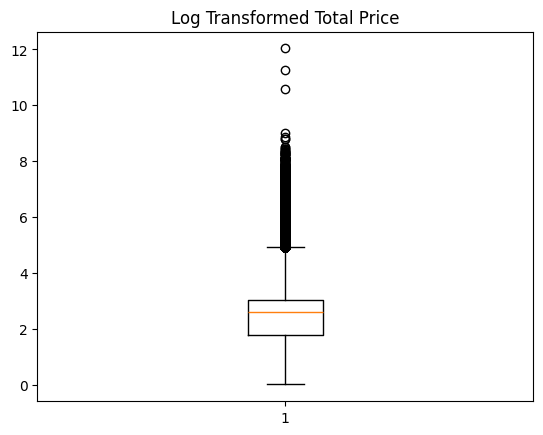

In [23]:
# Log transformation
df_log = df[df['TotalPrice'] > 0].copy()
df_log['Log_TotalPrice'] = np.log1p(df_log['TotalPrice'])

plt.boxplot(df_log['Log_TotalPrice'])
plt.title('Log Transformed Total Price')
plt.show()